# Validate against buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to Lauri buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Processed buoy pickles under `inputs/LauriBuoys/processed/`

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils import metamodel as mm
from utils import validation as val
from utils.config import SIMULATIONS, resolve

## Configuration

Map each SnapWave buoy site to a processed pickle. Keys must match mesh site ids
(e.g. `buoy_Apolima_Buoy`). Set `period` to overlap buoy records and dynamic output.

In [2]:
period = "2020-07"  # e.g. "1990-05" or "2020-05" — must match buoy + dynamic
offshore_name = "WHACS"
mda_n = 450
pca_variance = {"hs": 0.99, "dir": 0.99}

# Buoy sites to validate (subset of buoy_files keys)
sites = ["buoy_Aunuu_Buoy"]

# SnapWave site id → LauriBuoys processed pickle
buoy_files = {
    "buoy_Apolima_Buoy": (
        "inputs/LauriBuoys/processed/samoaapolima_lon187.8_lat-13.88_year1989_1990.pkl"
    ),
    "buoy_Aunuu_Buoy": "inputs/LauriBuoys/processed/americansita.nc",
}

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_fullaso.nc"
)

# Buoy pickles may lack direction — compare hs/tp only unless dir is present
variables = ["hs", "tp", "dir"]

print(f"period        : {period}")
print(f"mda_n         : {mda_n}")
print(f"sites         : {sites}")
print(f"dynamic path  : {dynamic_path}")
print(f"dynamic exists: {dynamic_path.is_file()}")

period        : 2020-07
mda_n         : 450
sites         : ['buoy_Aunuu_Buoy']
dynamic path  : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_fullaso.nc
dynamic exists: True


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)

## 2 · Load buoy observations

In [11]:
# buoy_files_active = {k: buoy_files[k] for k in sites}
# buoy = val.load_buoy_observations(buoy_files_active, time=period)

buoy = (
    xr.open_dataset("inputs/LauriBuoys/processed/americansita.nc")
    .rename({"dm": "dir"})
    .sel(time=period)
    .expand_dims({"sites": ["buoy_Aunuu_Buoy"]})
    .transpose("time", "sites")
)
buoy

<xarray.Dataset> Size: 21kB
Dimensions:  (sites: 1, time: 744)
Coordinates:
  * sites    (sites) object 8B 'buoy_Aunuu_Buoy'
  * time     (time) datetime64[ns] 6kB 2020-07-01 ... 2020-07-31T23:00:00
Data variables:
    hs       (time, sites) float64 6kB 1.885 1.81 1.836 ... 2.42 2.337 2.337
    tp       (time, sites) float32 3kB 8.181 8.711 8.716 ... 9.865 9.402 9.402
    dir      (time, sites) float64 6kB 124.0 126.8 127.9 ... 132.1 131.4 131.4
Attributes:
    standard_name:  sea_surface_wave_significant_height
    units:          m

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in ``Samoa.json`` —
currently WHACS only).

In [5]:
bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

spectral = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids)[[v for v in variables if v in dynamic]].load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=variables,
)
closest_goals

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk[[v for v in variables if v in bulk]],
    "Spectral metamodel": spectral[[v for v in variables if v in spectral]],
    "Dynamic SnapWave": dynamic,
}

2026-07-02 08:09:28,982 - Samoa.metamodel - INFO - Reconstruct time='2020-07' n=450 goals=['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11'] partitions=[-1] sites=1
INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for tp is lower than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for dir_v is bigger than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predictin

## 4 · Metrics vs buoy

In [12]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
)

summary = val.metrics_summary(results)
summary

2026-07-02 08:12:44,055 - Samoa.validation - INFO - Computed 3 validation metric row(s)
2026-07-02 08:12:44,060 - Samoa.validation - INFO - Computed 3 validation metric row(s)
2026-07-02 08:12:44,068 - Samoa.validation - INFO - Computed 3 validation metric row(s)
2026-07-02 08:12:44,076 - Samoa.validation - INFO - Computed 3 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label,model
0,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.277041,0.360178,0.285517,WHACS (closest goal),Buoy,WHACS (closest goal)
1,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,0.590612,2.199985,-0.090182,WHACS (closest goal),Buoy,WHACS (closest goal)
2,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,4.279641,12.467377,0.522553,WHACS (closest goal),Buoy,WHACS (closest goal)
3,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.078953,0.231658,0.716468,Bulk metamodel,Buoy,Bulk metamodel
4,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,0.576385,2.246788,-0.101633,Bulk metamodel,Buoy,Bulk metamodel
5,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,5.719187,13.666499,0.426293,Bulk metamodel,Buoy,Bulk metamodel
6,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.144581,0.264555,0.708784,Spectral metamodel,Buoy,Spectral metamodel
7,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,-0.400039,1.687595,0.034374,Spectral metamodel,Buoy,Spectral metamodel
8,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,15.013007,21.991786,-0.485581,Spectral metamodel,Buoy,Spectral metamodel
9,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.210755,0.299483,0.539289,Dynamic SnapWave,Buoy,Dynamic SnapWave


## 5 · Scatter plots

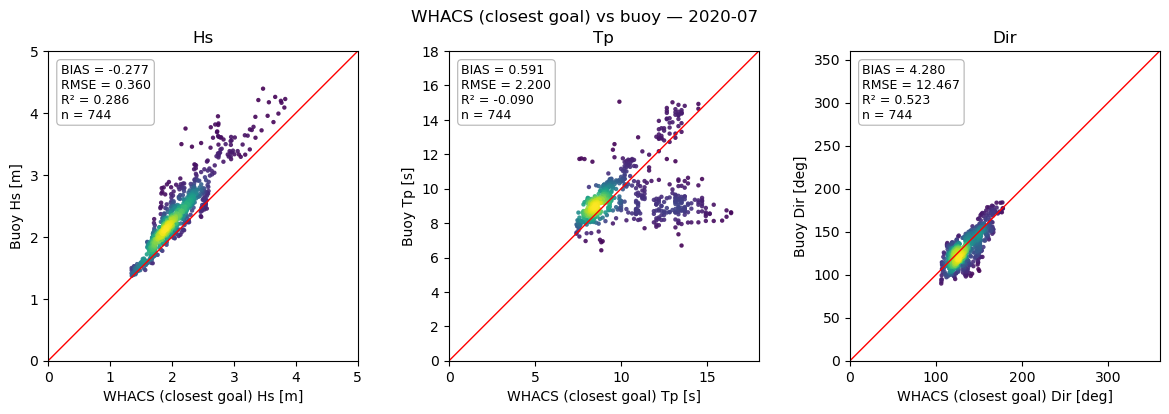

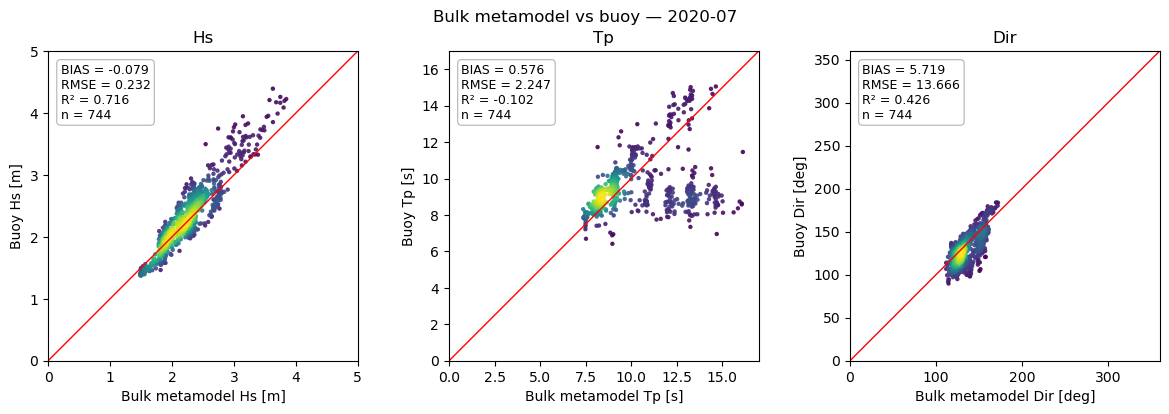

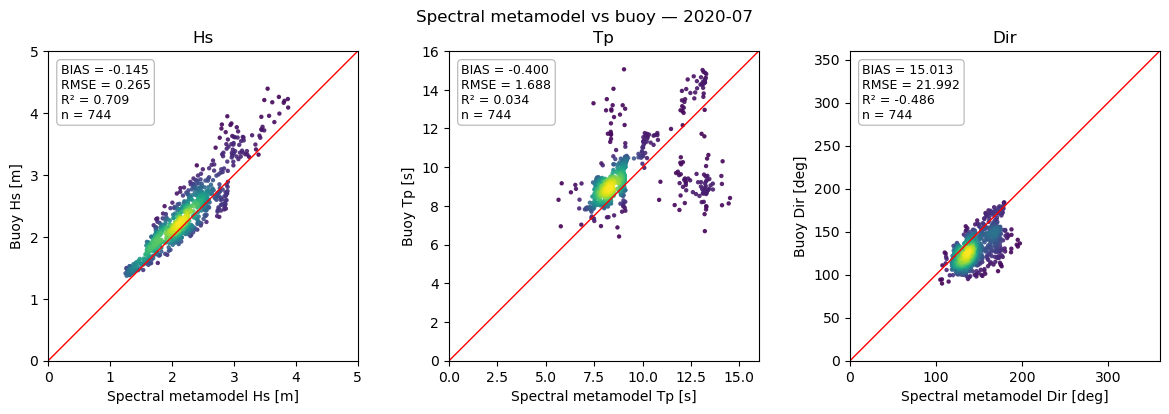

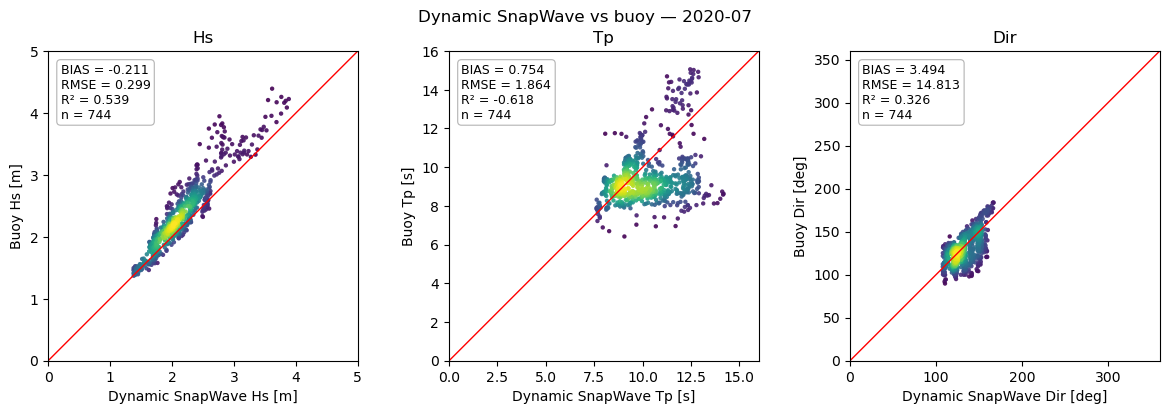

In [13]:
group = mm.resolve_sites(estimates["Bulk metamodel"], sites)[0]

for name, result in results.items():
    result.plot_scatter(
        group,
        variables=variables,
        estimate_label=name,
        reference_label="Buoy",
    )
    plt.suptitle(f"{name} vs buoy — {period}")
    plt.show()

## 6 · Time series

Line plots of buoy observations vs each model over the validation period.

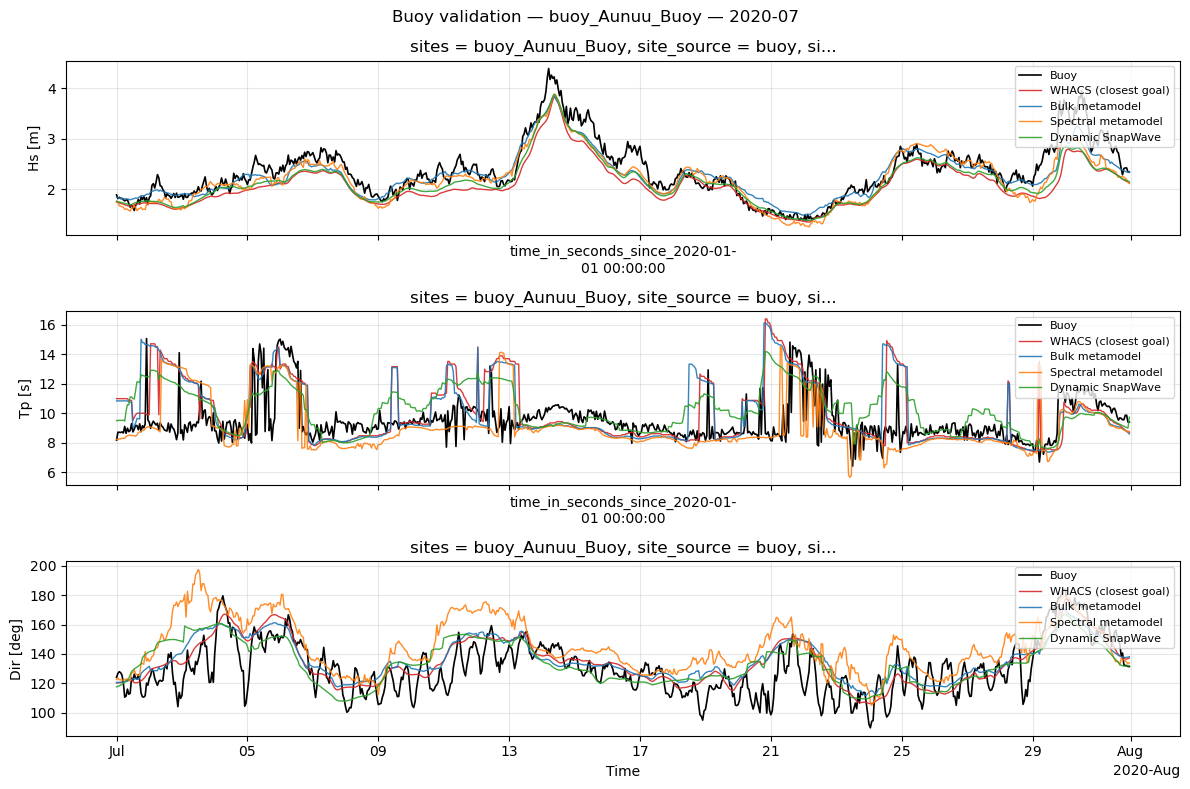

In [14]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()